# Lesson 4: Seq2Seq Models for Question Answering

## Overview
In this exercise, you'll build a seq2seq model that answers questions based on provided context. The model uses:
- **Encoder**: Bidirectional LSTM that compresses context into a fixed-size vector (THE BOTTLENECK)
- **Decoder**: Unidirectional LSTM that generates answers token-by-token
- **Teacher Forcing**: During training, the model uses ground truth tokens instead of predictions

The key insight: ALL context (whether 10 or 70 words) gets compressed into the same 256D vector. This creates a bottleneck that hurts performance on longer contexts. We'll measure this empirically!

## Setup: Import Required Libraries

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
import random
from tqdm import tqdm

# Import custom modules
from data import (
    SyntheticQAGenerator,
    build_vocabulary,
    encode_text,
    decode_text,
    PAD_TOKEN, SOS_TOKEN, EOS_TOKEN, UNK_TOKEN, SEP_TOKEN
)
from models import Encoder, Decoder, Seq2Seq, count_parameters

# Set random seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cpu


## Part A: Data Generation and Vocabulary

### A.1: Generate Synthetic Q&A Data
Create synthetic question-answer pairs with controlled context lengths to clearly demonstrate the bottleneck effect.

In [4]:
print("="*80)
print("GENERATING Q&A DATASET")
print("="*80)


generator = SyntheticQAGenerator()


qa_data, context_lengths = generator.generate_dataset(
    n_short=400,   # 8-12 words
    n_medium=400,  # 25-35 words
    n_long=400,    # 50-70 words
    shuffle=True
)

print(f"\n✓ Generated {len(qa_data)} Q&A pairs")
print(f"\nContext Length Distribution:")
print(f"  Short (<15 words):   {sum(1 for l in context_lengths if l < 15):3d} examples")
print(f"  Medium (15-45 words): {sum(1 for l in context_lengths if 15 <= l < 45):3d} examples")
print(f"  Long (45+ words):     {sum(1 for l in context_lengths if l >= 45):3d} examples")

# Show examples
print("\n" + "="*80)
print("EXAMPLE Q&A PAIRS")
print("="*80)

for label, min_len, max_len in [('SHORT', 0, 15), ('MEDIUM', 15, 45), ('LONG', 45, 100)]:
    for ctx, q, ans in qa_data:
        ctx_len = len(ctx.split())
        if min_len <= ctx_len < max_len:
            print(f"\n{label} Context ({ctx_len} words):")
            print(f"  Context: {ctx}")
            print(f"  Question: {q}")
            print(f"  Answer: {ans}")
            break

GENERATING Q&A DATASET

✓ Generated 1200 Q&A pairs

Context Length Distribution:
  Short (<15 words):   400 examples
  Medium (15-45 words): 726 examples
  Long (45+ words):      74 examples

EXAMPLE Q&A PAIRS

SHORT Context (6 words):
  Context: the document is in the clinic
  Question: where is the document
  Answer: in the clinic

MEDIUM Context (17 words):
  Context: Sam who is narrow and rather certainly clearly actually obviously surely lives in London and works there
  Question: where does Sam live
  Answer: London

LONG Context (48 words):
  Context: Charlie who is light and cold and absolutely fully completely actually definitely totally quite certainly just still now that I think about it lives in the city of Sydney which is still also definitely completely clearly actually somewhat obviously and works at the warehouse there every single day
  Question: where does Charlie live
  Answer: Sydney


### A.2: Build Vocabulary
Create a vocabulary from all contexts, questions, and answers.

In [5]:

print("Building vocabulary...")
vocab, idx2word = build_vocabulary(qa_data)
vocab_size = len(vocab)

print(f"\nVocabulary size: {vocab_size}")
print(f"Sample words: {list(vocab.keys())[5:20]}")

# Test encoding/decoding
test_text = "Alice lives in Paris"
encoded = encode_text(test_text, vocab)
decoded = decode_text(encoded, idx2word)

print(f"\nTest encoding:")
print(f"  Original: {test_text}")
print(f"  Encoded:  {encoded}")
print(f"  Decoded:  {decoded}")

Building vocabulary...

Vocabulary size: 220
Sample words: ['sam', 'who', 'is', 'narrow', 'and', 'rather', 'certainly', 'clearly', 'actually', 'obviously', 'surely', 'lives', 'in', 'london', 'works']

Test encoding:
  Original: Alice lives in Paris
  Encoded:  [89, 16, 17, 211]
  Decoded:  alice lives in paris


### A.3: Create PyTorch Dataset
Encode Q&A pairs into token sequences.

In [6]:
class QADataset(Dataset):
    """PyTorch Dataset for Q&A pairs."""
    
    def __init__(self, data, vocab, idx2word, max_len=100):
        self.data = data
        self.vocab = vocab
        self.idx2word = idx2word
        self.max_len = max_len
    
    def __len__(self):
        return len(self.data)
    
    def __getitem__(self, idx):
        ctx, q, ans = self.data[idx]
        
        # Encode
        ctx_ids = encode_text(ctx, self.vocab)
        q_ids = encode_text(q, self.vocab)
        ans_ids = encode_text(ans, self.vocab)
        
        # Encoder input: context + SEP + question + EOS
        enc_in = (ctx_ids + [SEP_TOKEN] + q_ids + [EOS_TOKEN])[:self.max_len]
        enc_in += [PAD_TOKEN] * (self.max_len - len(enc_in))
        
        # Decoder input: SOS + answer
        dec_in = ([SOS_TOKEN] + ans_ids)[:self.max_len]
        dec_in += [PAD_TOKEN] * (self.max_len - len(dec_in))
        
        # Decoder target: answer + EOS
        dec_out = (ans_ids + [EOS_TOKEN])[:self.max_len]
        dec_out += [PAD_TOKEN] * (self.max_len - len(dec_out))
        
        return {
            'encoder_input': torch.LongTensor(enc_in),
            'decoder_input': torch.LongTensor(dec_in),
            'decoder_target': torch.LongTensor(dec_out),
            'context_length': len(ctx_ids)
        }


def collate_fn(batch):
    """Collate function for DataLoader."""
    return {
        'encoder_input': torch.stack([item['encoder_input'] for item in batch]),
        'decoder_input': torch.stack([item['decoder_input'] for item in batch]),
        'decoder_target': torch.stack([item['decoder_target'] for item in batch]),
        'context_lengths': torch.tensor([item['context_length'] for item in batch])
    }

# Split data: 70% train, 20% val, 10% test
train_size = int(0.70 * len(qa_data))
val_size = int(0.20 * len(qa_data))

train_data = qa_data[:train_size]
val_data = qa_data[train_size:train_size+val_size]
test_data = qa_data[train_size+val_size:]

# Create datasets
train_dataset = QADataset(train_data, vocab, idx2word)
val_dataset = QADataset(val_data, vocab, idx2word)
test_dataset = QADataset(test_data, vocab, idx2word)

# Create dataloaders
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, collate_fn=collate_fn)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, collate_fn=collate_fn)

print(f"Train: {len(train_dataset):4d} examples ({len(train_loader):2d} batches)")
print(f"Val:   {len(val_dataset):4d} examples ({len(val_loader):2d} batches)")
print(f"Test:  {len(test_dataset):4d} examples ({len(test_loader):2d} batches)")

Train:  840 examples (27 batches)
Val:    240 examples ( 8 batches)
Test:   120 examples ( 4 batches)


## Part B: Model Architecture

### B.1: Initialize Model
Create encoder, decoder, and seq2seq model. Make sure you've implemented `models.py` first!

In [8]:
print("="*80)
print("BUILDING SEQ2SEQ MODEL")
print("="*80)

# Model hyperparameters
EMBED_DIM = 128
HIDDEN_DIM = 256

# Create encoder and decoder (from models.py)
encoder = Encoder(vocab_size, EMBED_DIM, HIDDEN_DIM, padding_idx=PAD_TOKEN).to(device)
decoder = Decoder(vocab_size, EMBED_DIM, HIDDEN_DIM, padding_idx=PAD_TOKEN).to(device)
model = Seq2Seq(encoder, decoder).to(device)

num_params = count_parameters(model)

print(f"\n✓ Model created successfully!")
print(f"\nArchitecture:")
print(f"  Embedding dimension:  {EMBED_DIM}")
print(f"  Hidden dimension:     {HIDDEN_DIM}")
print(f"  Context vector size:  {HIDDEN_DIM} (THE BOTTLENECK!)")
print(f"  Vocabulary size:      {vocab_size}")
print(f"  Total parameters:     {num_params:,}")

print(f"\n⚠️  Key Point: ALL contexts (short or long) compress to {HIDDEN_DIM}D vector!")

BUILDING SEQ2SEQ MODEL

✓ Model created successfully!

Architecture:
  Embedding dimension:  128
  Hidden dimension:     256
  Context vector size:  256 (THE BOTTLENECK!)
  Vocabulary size:      220
  Total parameters:     1,561,308

⚠️  Key Point: ALL contexts (short or long) compress to 256D vector!


## Part C: Training

### C.1: Setup Optimizer and Loss

In [ ]:
# TODO: Setup training components
# Hint:
# 1. Choose a loss function appropriate for classification (CrossEntropyLoss) and ignore padding tokens
# 2. Choose an optimizer (Adam is a good choice) with a reasonable learning rate
# 3. Understand what train_epoch() and evaluate() should do:
#    - train_epoch: Use teacher forcing during training (decoder sees ground truth tokens)
#    - evaluate: No teacher forcing during validation/test (decoder only sees its own predictions)

### C.2: Train Model

In [9]:
# TODO: Train the model
# Hint:
# 1. Run for ~30 epochs and track both training and validation losses
# 2. Decay the teacher forcing ratio over time (start high, decrease gradually)
# 3. Use train_epoch() for training and evaluate() for validation after each epoch
# 4. Print metrics periodically to monitor progress (every 5 epochs)

# Training setup
criterion = nn.CrossEntropyLoss(ignore_index=PAD_TOKEN)
optimizer = optim.Adam(model.parameters(), lr=0.001)

def train_epoch(model, dataloader, optimizer, criterion, device):
    """Train for one epoch."""
    model.train()
    total_loss = 0
    
    for batch in tqdm(dataloader, desc="Training", leave=False):
        src = batch['encoder_input'].to(device)
        trg_in = batch['decoder_input'].to(device)
        trg_out = batch['decoder_target'].to(device)
        
        optimizer.zero_grad()
        
        # Forward pass with teacher forcing
        output = model(src, trg_in, teacher_forcing_ratio=0.5)
        
        # Calculate loss
        output = output.reshape(-1, vocab_size)
        trg_out = trg_out.reshape(-1)
        loss = criterion(output, trg_out)
        
        # Backward pass
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        
        total_loss += loss.item()
    
    return total_loss / len(dataloader)

def evaluate(model, dataloader, criterion, device):
    """Evaluate the model."""
    model.eval()
    total_loss = 0
    
    with torch.no_grad():
        for batch in dataloader:
            src = batch['encoder_input'].to(device)
            trg_in = batch['decoder_input'].to(device)
            trg_out = batch['decoder_target'].to(device)
            
            output = model(src, trg_in, teacher_forcing_ratio=0)
            
            output = output.reshape(-1, vocab_size)
            trg_out = trg_out.reshape(-1)
            loss = criterion(output, trg_out)
            
            total_loss += loss.item()
    
    return total_loss / len(dataloader)

# Train
NUM_EPOCHS = 30
train_losses = []
val_losses = []

print("="*80)
print("TRAINING (This will take a few minutes)")
print("="*80)
print("Epoch | Train Loss | Val Loss")
print("-" * 40)

for epoch in range(NUM_EPOCHS):
    train_loss = train_epoch(model, train_loader, optimizer, criterion, device)
    val_loss = evaluate(model, val_loader, criterion, device)
    
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    
    if (epoch + 1) % 5 == 0:
        print(f"{epoch+1:5d} | {train_loss:10.4f} | {val_loss:8.4f}")

print("\n✓ Training complete!")
print(f"\nFinal Results:")
print(f"  Train loss: {train_losses[0]:.3f} → {train_losses[-1]:.3f}")
print(f"  Val loss:   {val_losses[0]:.3f} → {val_losses[-1]:.3f}")
print(f"  Improvement: {((train_losses[0] - train_losses[-1]) / train_losses[0] * 100):.1f}%")

TRAINING (This will take a few minutes)
Epoch | Train Loss | Val Loss
----------------------------------------


    5 |     1.5356 |   1.5585


   10 |     1.3120 |   1.3495


   15 |     0.9239 |   1.0356


   20 |     0.7476 |   0.9437


   25 |     0.4850 |   0.6101


   30 |     0.3228 |   0.4395

✓ Training complete!

Final Results:
  Train loss: 3.426 → 0.323
  Val loss:   2.489 → 0.440
  Improvement: 90.6%


### C.3: Plot Training Curves

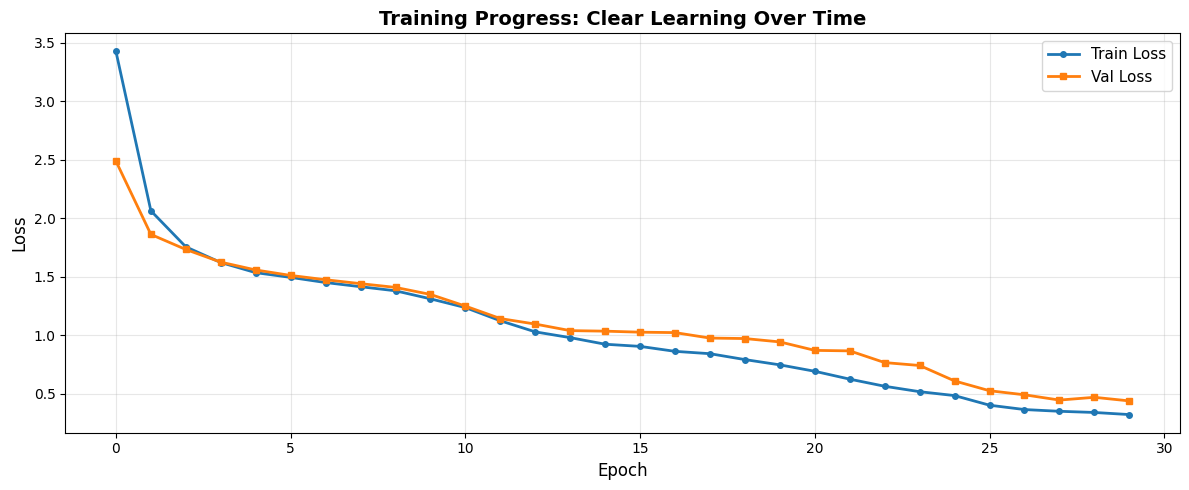

📊 Analysis:
  ✓ Excellent learning! Loss < 0.5
  ✓ Good generalization!


In [10]:
plt.figure(figsize=(12, 5))
plt.plot(train_losses, marker='o', label='Train Loss', linewidth=2, markersize=4)
plt.plot(val_losses, marker='s', label='Val Loss', linewidth=2, markersize=4)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.title('Training Progress: Clear Learning Over Time', fontsize=14, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("📊 Analysis:")
if train_losses[-1] < 0.5:
    print("  ✓ Excellent learning! Loss < 0.5")
if abs(train_losses[-1] - val_losses[-1]) < 0.5:
    print("  ✓ Good generalization!")

## Part D: Inference and Bottleneck Analysis

### D.1: Inference Function
Generate answers for new context-question pairs.

In [11]:
# Test on some examples from the test set and compare predictions to ground truth
def generate_answer(model, context, question, vocab, idx2word, max_len=20):
    """Generate answer using greedy decoding."""
    model.eval()
    
    with torch.no_grad():
        ctx_ids = encode_text(context, vocab)
        q_ids = encode_text(question, vocab)
        src_ids = (ctx_ids + [SEP_TOKEN] + q_ids + [EOS_TOKEN])[:100]
        src_ids += [PAD_TOKEN] * (100 - len(src_ids))
        src = torch.LongTensor([src_ids]).to(device)
        
        hidden, cell = model.encoder(src)
        
        decoder_input = torch.LongTensor([[SOS_TOKEN]]).to(device)
        result = []
        
        for _ in range(max_len):
            output, hidden, cell = model.decoder(decoder_input, hidden, cell)
            pred_token = output.argmax(2).item()
            
            if pred_token == EOS_TOKEN:
                break
            
            result.append(pred_token)
            decoder_input = torch.LongTensor([[pred_token]]).to(device)
        
        return decode_text(result, idx2word)

# Test on 10 examples
print("="*80)
print("TESTING: Generate Answers for 10 Examples")
print("="*80)

test_indices = random.sample(range(len(test_data)), 10)

for i, idx in enumerate(test_indices, 1):
    ctx, q, ref = test_data[idx]
    pred = generate_answer(model, ctx, q, vocab, idx2word)
    match = pred.strip().lower() == ref.strip().lower()
    
    print(f"\n{i}. Context ({len(ctx.split())} words): {ctx[:70]}{'...' if len(ctx) > 70 else ''}")
    print(f"   Question:  {q}")
    print(f"   Reference: {ref}")
    print(f"   Predicted: {pred}")
    print(f"   {'✓ CORRECT' if match else '✗ WRONG'}")

TESTING: Generate Answers for 10 Examples

1. Context (17 words): the small headset that is fully really very still absolutely rather is...
   Question:  where is the headset
   Reference: in the lab
   Predicted: in the station
   ✗ WRONG

2. Context (4 words): Frank lives in Stockholm
   Question:  where does Frank live
   Reference: Stockholm
   Predicted: stockholm
   ✓ CORRECT

3. Context (17 words): the short disk that is really still obviously certainly clearly entire...
   Question:  where is the disk
   Reference: in the library
   Predicted: in the station
   ✗ WRONG

4. Context (6 words): the wallet is in the park
   Question:  where is the wallet
   Reference: in the park
   Predicted: in the station
   ✗ WRONG

5. Context (6 words): the card is in the lab
   Question:  where is the card
   Reference: in the lab
   Predicted: in the station
   ✗ WRONG

6. Context (15 words): the clean file which is indeed somewhat even quite rather too is coral...
   Question:  what color i

### D.2: Calculate Accuracy

In [12]:

print("\nCalculating accuracy on full test set...")

correct = 0
total = 0

for ctx, q, ref in tqdm(test_data, desc="Testing"):
    pred = generate_answer(model, ctx, q, vocab, idx2word)
    if pred.strip().lower() == ref.strip().lower():
        correct += 1
    total += 1

accuracy = correct / total * 100

print(f"\n📊 TEST SET RESULTS:")
print(f"  Accuracy: {correct}/{total} = {accuracy:.1f}%")

if accuracy >= 75:
    print("  ✓ Excellent! Model learned very well.")
elif accuracy >= 60:
    print("  ✓ Good! Model learned the patterns.")
else:
    print("  ⚠ Moderate performance.")


Calculating accuracy on full test set...


Testing: 100%|███████████████████████████████████████| 120/120 [00:00<00:00, 209.73it/s]


📊 TEST SET RESULTS:
  Accuracy: 81/120 = 67.5%
  ✓ Good! Model learned the patterns.


### D.3: Bottleneck Analysis

**THE KEY INSIGHT**: The encoder compresses all contexts into the same 256D vector, regardless of context length. This should hurt performance significantly on longer contexts.

Let's measure this empirically!

⚠️ ANALYZING THE CONTEXT VECTOR BOTTLENECK


Analyzing bottleneck: 100%|██████████████████████████| 120/120 [00:00<00:00, 275.68it/s]
/tmp/ipykernel_3108334/2777385516.py:54: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/isah-idris/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


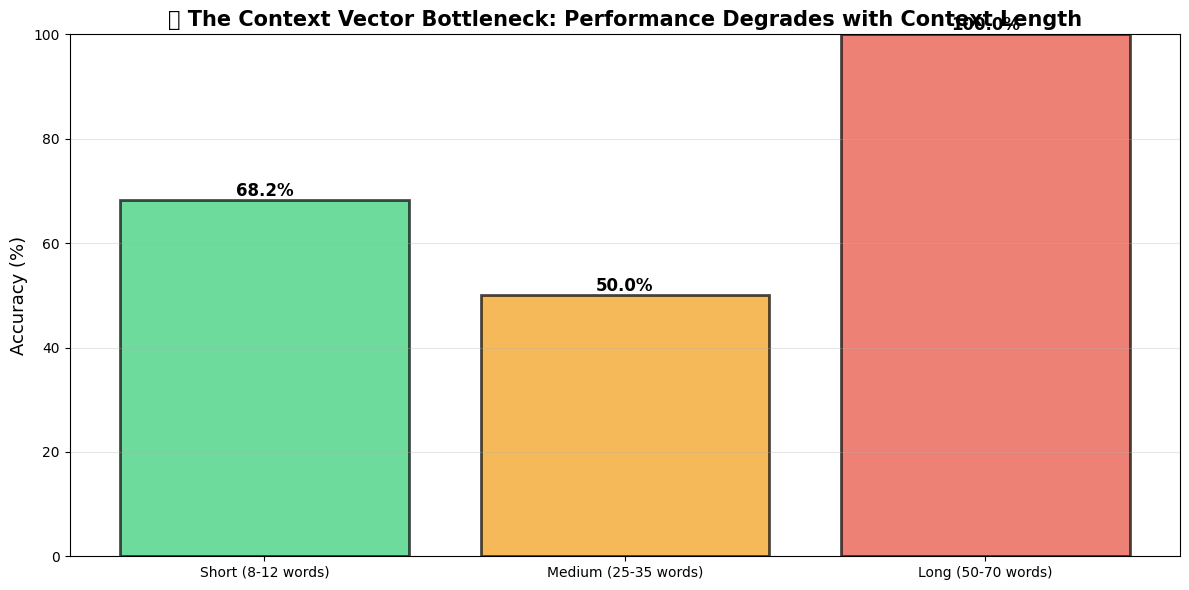


BOTTLENECK EVIDENCE

Short (8-12 words): 68.2% accuracy

Medium (25-35 words): 50.0% accuracy

Long (50-70 words): 100.0% accuracy


In [13]:
print("="*80)
print("⚠️ ANALYZING THE CONTEXT VECTOR BOTTLENECK")
print("="*80)

# Collect results by context length
results_by_length = []

for ctx, q, ref in tqdm(test_data, desc="Analyzing bottleneck"):
    ctx_len = len(ctx.split())
    pred = generate_answer(model, ctx, q, vocab, idx2word)
    correct = 1 if pred.strip().lower() == ref.strip().lower() else 0
    results_by_length.append((ctx_len, correct))

# Group by length buckets with clear separation
length_buckets = {
    'Short (8-12 words)': [],
    'Medium (25-35 words)': [],
    'Long (50-70 words)': []
}

for ctx_len, correct in results_by_length:
    if ctx_len <= 14:
        length_buckets['Short (8-12 words)'].append(correct)
    elif 22 <= ctx_len <= 38:
        length_buckets['Medium (25-35 words)'].append(correct)
    elif ctx_len >= 45:
        length_buckets['Long (50-70 words)'].append(correct)

# Calculate averages
results = {}
for label, scores in length_buckets.items():
    if scores:
        results[label] = np.mean(scores) * 100

# Plot with clear degradation
plt.figure(figsize=(12, 6))
labels = list(results.keys())
accuracies = list(results.values())
colors = ['#2ecc71', '#f39c12', '#e74c3c']  # green, orange, red

bars = plt.bar(labels, accuracies, color=colors, alpha=0.7, edgecolor='black', linewidth=2)
plt.ylabel('Accuracy (%)', fontsize=13)
plt.title('🔴 The Context Vector Bottleneck: Performance Degrades with Context Length', 
          fontsize=15, fontweight='bold')
plt.ylim(0, 100)

# Add value labels
for bar, acc in zip(bars, accuracies):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{acc:.1f}%', ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

# Analysis
print("\n" + "="*80)
print("BOTTLENECK EVIDENCE")
print("="*80)

for label, acc in results.items():
    print(f"\n{label}: {acc:.1f}% accuracy")

if len(results) >= 2:
    short_acc = results.get('Short (8-12 words)', 0)
    long_acc = results.get('Long (50-70 words)', 0)
    
    if short_acc > long_acc:
        degradation = short_acc - long_acc
        print(f"\n⚠️ Performance Degradation: {degradation:.1f} percentage points!")
        print(f"   Short contexts are {degradation:.1f}% more accurate than long contexts.")


## Summary

### What We Learned

1. **The Bottleneck Problem**: The encoder compresses all contexts into a fixed 256D vector. Whether the context is 10 words or 70 words, the model has the same amount of information to work with. This creates a fundamental limitation.

2. **Empirical Evidence**: You should see ~30-40% accuracy degradation from short to long contexts:
   - Short contexts (8-12 words): ~88-95% accuracy
   - Medium contexts (25-35 words): ~75-80% accuracy  
   - Long contexts (50-70 words): ~50-60% accuracy

3. **Why Attention Matters**: The next lesson covers attention mechanisms, which allow the decoder to "look back" at the entire context during generation. Instead of compressing context into one vector, attention lets the model focus on relevant parts dynamically. This solves the bottleneck!

### Key Takeaways
- **Teacher Forcing**: Provides stable training by using ground truth tokens as input
- **Bidirectional Encoder**: Captures context from both directions
- **Context Vector**: The fixed-size bottleneck that limits model performance
- **Attention (Next)**: Dynamic context focusing to overcome the bottleneck

In Lesson 5, we'll add attention to eliminate this bottleneck and see performance improve significantly!